# ML 02 - Anomaly Detection (Unsupervised) on Industrial Sensors and Supply-Chain Orders

**Objective:** detect abnormal records without using labels to fit the models, and check the detectors in two ways:
1. **AI4I 2020 machine data (10,000 records):** there is a known failure label, used *only to evaluate* the unsupervised scores (never as a feature or for tuning).
2. **Kaizen order data (33,919 orders):** there are no labels, so detectors are validated by **injecting synthetic anomalies** (order quantities inflated by a known factor) and measuring how many are recovered, and then the top real flagged orders are reviewed.

**Detectors:** Isolation Forest, Local Outlier Factor, robust z-score (max |z| across features / MAD z per SKU) and a robust Mahalanobis distance (Minimum Covariance Determinant).

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import MinCovDet
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

sns.set_theme(style="whitegrid")
OUT = Path(".")
SEED = 42
def find(rel_local, rel_repo):
    for p in (Path(rel_local), Path(rel_repo)):
        if p.exists(): return p
    raise FileNotFoundError(rel_repo)
AI4I = find("ai4i2020.csv", "../../python/05_predictive_maintenance/ai4i2020.csv")
XLSX = find("dataset_kaizen analytics.xlsx", "../../python/02_inventory_optimization/dataset_kaizen analytics.xlsx")
print(AI4I, "|", XLSX)

..\..\python\05_predictive_maintenance\ai4i2020.csv | ..\..\python\02_inventory_optimization\dataset_kaizen analytics.xlsx


## Part A - AI4I 2020 sensor data (labelled sanity check)

### A1. Data and features
Features are the 5 raw sensor/process variables plus two physically motivated ones (temperature difference and mechanical power = torque x angular speed). `TWF/HDF/PWF/OSF/RNF` failure-mode flags and `Machine failure` are **excluded from the feature set** (they define the label); they are used only to score the detectors afterwards.

In [2]:
d = pd.read_csv(AI4I)
print("shape:", d.shape, "| missing:", int(d.isna().sum().sum()), "| duplicated rows:", int(d.duplicated().sum()))
d["temp_diff"] = d["Process temperature [K]"] - d["Air temperature [K]"]
d["power_W"] = d["Torque [Nm]"] * d["Rotational speed [rpm]"] * 2 * np.pi / 60
FEATS = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]", "temp_diff", "power_W"]
y = d["Machine failure"].values
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print("failure rate: %.2f%% (%d of %d)" % (100 * y.mean(), y.sum(), len(y)))
print("failures per mode:", d[modes].sum().to_dict())
Z = StandardScaler().fit_transform(d[FEATS])   # unsupervised scaling, labels not involved

shape: (10000, 14) | missing: 0 | duplicated rows: 0
failure rate: 3.39% (339 of 10000)
failures per mode: {'TWF': 46, 'HDF': 115, 'PWF': 95, 'OSF': 98, 'RNF': 19}


### A2. Fit detectors (no labels) and score
Hyper-parameters are **fixed a priori** (not tuned on the label): Isolation Forest 300 trees; LOF `n_neighbors=100` (~sqrt(n)); MCD support fraction 0.75. A sensitivity check on LOF's `n_neighbors` follows, so the reader can see the result does not hinge on one value. Higher score = more anomalous.

In [3]:
scores = {}
scores["Isolation Forest"] = -IsolationForest(n_estimators=300, random_state=SEED).fit(Z).score_samples(Z)
scores["LOF (k=100)"] = -LocalOutlierFactor(n_neighbors=100).fit(Z).negative_outlier_factor_
scores["Max |z-score|"] = np.abs(Z).max(axis=1)
scores["Robust Mahalanobis (MCD)"] = MinCovDet(support_fraction=0.75, random_state=SEED).fit(Z).mahalanobis(Z)

K = int(round(len(d) * y.mean()))   # review budget = expected anomaly share (3.39%); a real deployment would pick it from inspection capacity
rows = []
for name, s in scores.items():
    top = np.argsort(-s)[:K]
    rows.append({"Detector": name, "ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
                 f"Precision@{K}": y[top].mean(), f"Recall@{K}": y[top].sum() / y.sum(),
                 "Lift vs random": y[top].mean() / y.mean()})
res_a = pd.DataFrame(rows).set_index("Detector")
print(f"Base rate (random detector) PR-AUC = {y.mean():.4f}; review budget K = {K} records (top {100*K/len(d):.2f}%)")
display(res_a.round(3))
res_a.round(4).to_csv(OUT / "metrics_ai4i_unsupervised.csv")

print("LOF sensitivity to n_neighbors (ROC-AUC / PR-AUC):")
for k in [20, 50, 100, 200]:
    s = -LocalOutlierFactor(n_neighbors=k).fit(Z).negative_outlier_factor_
    print(f"  k={k:3d}: ROC-AUC {roc_auc_score(y, s):.3f} | PR-AUC {average_precision_score(y, s):.3f}")

Base rate (random detector) PR-AUC = 0.0339; review budget K = 339 records (top 3.39%)


,ROC-AUC,PR-AUC,Precision@339,Recall@339,Lift vs random
Detector,,,,,
Isolation Forest,0.855,0.226,0.274,0.274,8.093
LOF (k=100),0.860,0.289,0.324,0.324,9.572
Max |z-score|,0.851,0.232,0.286,0.286,8.441
Robust Mahalanobis (MCD),0.828,0.187,0.136,0.136,4.003


LOF sensitivity to n_neighbors (ROC-AUC / PR-AUC):
  k= 20: ROC-AUC 0.790 | PR-AUC 0.199


  k= 50: ROC-AUC 0.846 | PR-AUC 0.263


  k=100: ROC-AUC 0.860 | PR-AUC 0.289


  k=200: ROC-AUC 0.861 | PR-AUC 0.303


In [4]:
# Which failure modes are caught? Recall of each mode among the top-K flagged by each detector
mode_rows = {}
for name, s in scores.items():
    top = np.zeros(len(d), bool); top[np.argsort(-s)[:K]] = True
    mode_rows[name] = {f"{m} (n={int(d[m].sum())})": top[d[m].values == 1].mean() for m in modes if d[m].sum() > 0}
mode_df = pd.DataFrame(mode_rows).T
print("Share of each failure mode that lands in the top-K flagged records:")
display(mode_df.round(3))
mode_df.round(4).to_csv(OUT / "metrics_ai4i_recall_by_failure_mode.csv")

# supervised reference (upper bound, NOT comparable as 'unsupervised'): stratified 5-fold CV random forest, same features
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
p = cross_val_predict(RandomForestClassifier(300, class_weight="balanced", random_state=SEED, n_jobs=-1), d[FEATS], y, cv=cv, method="predict_proba")[:, 1]
print("Supervised reference (RF, 5-fold CV): ROC-AUC %.3f | PR-AUC %.3f" % (roc_auc_score(y, p), average_precision_score(y, p)))
sup_ref = {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p)}

Share of each failure mode that lands in the top-K flagged records:


,TWF (n=46),HDF (n=115),PWF (n=95),OSF (n=98),RNF (n=19)
Isolation Forest,0.043,0.113,0.726,0.235,0.0
LOF (k=100),0.152,0.113,0.811,0.347,0.0
Max |z-score|,0.065,0.043,0.937,0.163,0.0
Robust Mahalanobis (MCD),0.065,0.009,0.411,0.051,0.0


Supervised reference (RF, 5-fold CV): ROC-AUC 0.974 | PR-AUC 0.850


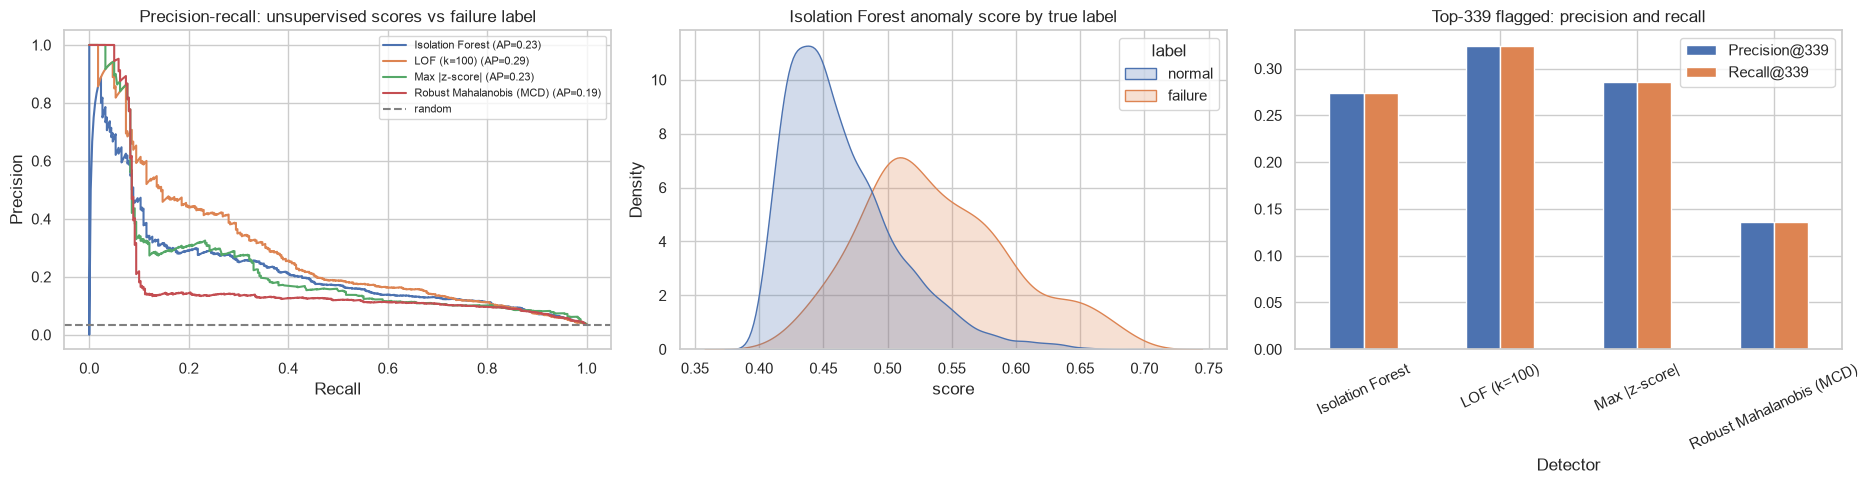

Flagged by IF: 339 | true failures among them: 93


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
best = res_a["PR-AUC"].idxmax()
for name, s in scores.items():
    pr, rc, _ = precision_recall_curve(y, s); ax[0].plot(rc, pr, label=f"{name} (AP={average_precision_score(y, s):.2f})")
ax[0].axhline(y.mean(), color="grey", ls="--", label="random"); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Precision-recall: unsupervised scores vs failure label"); ax[0].legend(fontsize=8)
sdf = pd.DataFrame({"score": scores["Isolation Forest"], "label": np.where(y == 1, "failure", "normal")})
sns.kdeplot(data=sdf, x="score", hue="label", common_norm=False, fill=True, ax=ax[1]); ax[1].set_title("Isolation Forest anomaly score by true label")
res_a[[c for c in res_a.columns if c.startswith("Precision@") or c.startswith("Recall@")]].plot.bar(ax=ax[2]); ax[2].set_title(f"Top-{K} flagged: precision and recall"); ax[2].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.savefig(OUT / "01_ai4i_detector_comparison.png", dpi=130); plt.show()

top_if = np.argsort(-scores["Isolation Forest"])[:K]
out = d[["UDI", "Type"] + FEATS + ["Machine failure"] + modes].copy()
for n, s in scores.items(): out["score_" + n.split(" (")[0].replace(" ", "_").replace("|", "").replace("-", "")] = s
out["flag_isolation_forest_topK"] = 0; out.iloc[top_if, out.columns.get_loc("flag_isolation_forest_topK")] = 1
out.to_csv(OUT / "ai4i_anomaly_scores.csv", index=False)
print("Flagged by IF:", len(top_if), "| true failures among them:", int(y[top_if].sum()))

## Part B - Kaizen order quantities (no labels: synthetic-injection validation)

### B1. Features
Order quantities span 0.00002 to 111,770 units (median 6, heavy tailed, many fractional kg orders), and the unit price is constant per SKU (price ratio = 1.0 for all orders), so unit price carries no anomaly signal. An order is only unusual **relative to its SKU**, so the features are:
- `log_q` = ln(order quantity)
- `rel` = `log_q` minus the SKU median `log_q` (how many log-units above/below the SKU's normal order)
- `sku_med` = SKU median `log_q` (scale of the SKU)
SKUs with fewer than 10 orders use the global median as reference.

In [6]:
s = pd.read_excel(XLSX, sheet_name="Sales Data").iloc[:, :8]
s.columns = s.columns.str.strip()
print("orders:", len(s), "| SKUs:", s["SKU ID"].nunique(), "| qty<=0:", int((s["Order Quantity"] <= 0).sum()))
print("unit price / SKU median price: min %.3f max %.3f" % ((s["Unit Sale Price"] / s.groupby("SKU ID")["Unit Sale Price"].transform("median")).min(),
                                                          (s["Unit Sale Price"] / s.groupby("SKU ID")["Unit Sale Price"].transform("median")).max()))

def make_features(qty, sku):
    lq = np.log(qty)
    g = pd.DataFrame({"sku": sku.values, "lq": lq})
    n = g.groupby("sku")["lq"].transform("size")
    med = g.groupby("sku")["lq"].transform("median")
    med = np.where(n >= 10, med, np.median(lq))
    rel = lq - med
    return pd.DataFrame({"log_q": lq, "rel": rel, "sku_med": med})

def sku_mad_z(F, sku, signed=False):
    # modified z-score of `rel` with a per-SKU MAD (floored at half the pooled MAD for stability)
    g = pd.DataFrame({"sku": sku.values, "rel": F["rel"].values})
    n = g.groupby("sku")["rel"].transform("size")
    mad = g.assign(a=g["rel"].abs()).groupby("sku")["a"].transform("median")
    pooled = np.median(np.abs(F["rel"]))
    mad = np.where(n >= 20, np.maximum(mad, 0.5 * pooled), pooled)
    z = 0.6745 * F["rel"].values / mad
    return z if signed else np.abs(z)

def detect(F, sku, seed=SEED):
    Zf = StandardScaler().fit_transform(F.values)
    return {"Isolation Forest": -IsolationForest(n_estimators=200, random_state=seed, n_jobs=-1).fit(Zf).score_samples(Zf),
            "LOF (k=50)": -LocalOutlierFactor(n_neighbors=50, n_jobs=-1).fit(Zf).negative_outlier_factor_,
            "SKU MAD z-score": sku_mad_z(F, sku),
            "SKU MAD z (upper tail)": sku_mad_z(F, sku, signed=True)}

F0 = make_features(s["Order Quantity"].values, s["SKU ID"])
sc0 = detect(F0, s["SKU ID"])
print(F0.describe().round(2))

orders: 33919 | SKUs: 290 | qty<=0: 0
unit price / SKU median price: min 1.000 max 1.000


          log_q       rel   sku_med
count  33919.00  33919.00  33919.00
mean       2.30     -0.12      2.41
std        2.47      1.12      2.24
min      -11.13    -10.69     -0.68
25%        0.69     -0.64      1.10
50%        1.79      0.00      1.62
75%        3.59      0.47      3.91
max       11.62      9.60      9.70


### B2. Validation by injection
For each magnitude (x3, x10, x30) I multiply the quantity of a random 1% of orders by that factor (simulating keying errors / unit-of-measure mistakes / bulk orders), refit every detector **on the contaminated data without telling it which rows changed**, and measure how many injected rows are in the top-2% flagged (a review budget of twice the injection rate). 5 random seeds per magnitude. Caveat: natural anomalies already in the data count as false positives in this test, so the precision figures are a lower bound.

ROC-AUC        PR-AUC        recall@2%       
                                 mean    std   mean    std      mean    std
factor detector                                                            
3      Isolation Forest         0.686  0.020  0.018  0.002     0.043  0.011
       LOF (k=50)               0.644  0.014  0.033  0.007     0.100  0.021
       SKU MAD z (upper tail)   0.820  0.013  0.063  0.005     0.154  0.015
       SKU MAD z-score          0.743  0.011  0.025  0.002     0.035  0.013
10     Isolation Forest         0.867  0.011  0.055  0.011     0.113  0.028
       LOF (k=50)               0.618  0.016  0.018  0.002     0.026  0.003
       SKU MAD z (upper tail)   0.937  0.007  0.208  0.011     0.516  0.019
       SKU MAD z-score          0.893  0.010  0.081  0.006     0.162  0.009
30     Isolation Forest         0.942  0.008  0.150  0.051     0.239  0.053
       LOF (k=50)               0.611  0.013  0.017  0.002     0.008  0.007
       SKU MAD z (upper tail)   0.974  0.004  0.395  0.016     0.756  0.011
       SKU MAD z-score          0.951  0.004  0.201  0.013     0.435  0.028

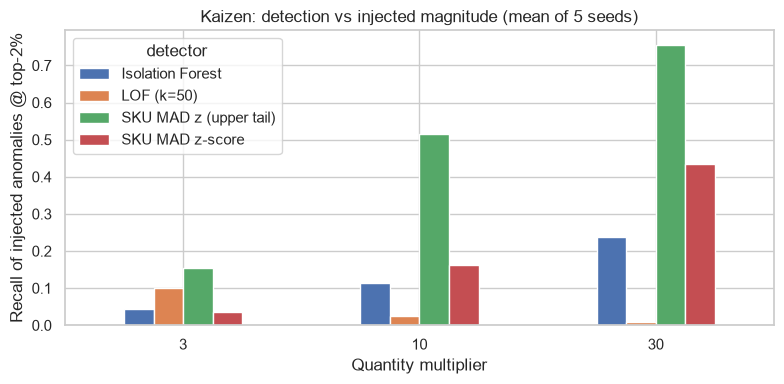

In [7]:
BUDGET = 0.02
rows = []
for factor in [3, 10, 30]:
    for seed in range(5):
        rng = np.random.default_rng(1000 + seed)
        idx = rng.choice(len(s), size=int(0.01 * len(s)), replace=False)
        q = s["Order Quantity"].values.copy(); q[idx] *= factor
        lab = np.zeros(len(s), int); lab[idx] = 1
        F = make_features(q, s["SKU ID"])
        for name, sc in detect(F, s["SKU ID"], seed).items():
            top = np.argsort(-sc)[:int(BUDGET * len(s))]
            rows.append({"factor": factor, "seed": seed, "detector": name, "ROC-AUC": roc_auc_score(lab, sc),
                         "PR-AUC": average_precision_score(lab, sc), "recall@2%": lab[top].sum() / lab.sum()})
inj = pd.DataFrame(rows)
inj_sum = inj.groupby(["factor", "detector"])[["ROC-AUC", "PR-AUC", "recall@2%"]].agg(["mean", "std"]).round(3)
display(inj_sum)
inj.to_csv(OUT / "metrics_kaizen_injection_runs.csv", index=False)
inj_sum.to_csv(OUT / "metrics_kaizen_injection_summary.csv")

piv = inj.groupby(["factor", "detector"])["recall@2%"].mean().unstack()
ax = piv.plot.bar(figsize=(8, 4)); ax.set_ylabel("Recall of injected anomalies @ top-2%"); ax.set_title("Kaizen: detection vs injected magnitude (mean of 5 seeds)"); ax.set_xlabel("Quantity multiplier"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(OUT / "02_kaizen_injection_recall.png", dpi=130); plt.show()

### B3. Real orders flagged on the original data
Top 1% (339 orders) by Isolation Forest, with the agreement between detectors and a look at what they are.

Overlap of top-1% sets (number of orders):


,Isolation Forest,LOF (k=50),SKU MAD z-score,SKU MAD z (upper tail)
Isolation Forest,339,0,158,47
LOF (k=50),0,339,0,0
SKU MAD z-score,158,0,339,122
SKU MAD z (upper tail),47,0,122,339


Flagged by >=2 detectors: 257 | number of detectors flagging each order (among flagged): {1: 807, 2: 222, 3: 35}

Top-1% IF orders: 148 are ABOVE and 191 BELOW the SKU's median order size; 75 are > 10x and 183 are < 0.1x the SKU median
Orders with quantity < 1 unit in the whole file: 3023 (8.9%) - fractional entries (kg) or unit-of-measure mismatches
Share of flagged orders by customer type: {'Wholesale': 0.528, 'Distributor': 0.33, 'Export': 0.142} | all orders: {'Wholesale': 0.536, 'Distributor': 0.314, 'Export': 0.15}
Top-10 by Isolation Forest (both tails):


,Order Number,Order Date,SKU ID,Warehouse ID,Customer Type,Order Quantity,x_sku_median,mad_z,n_detectors
22148,SO - 041048,2022-05-31,3178CA,GUT930,Distributor,0.0000,0.0000,16.4382,2
29161,SO - 048061,2022-11-10,3205AA,AXW291,Distributor,0.0034,0.0067,7.4524,2
15812,SO - 034712,2022-01-03,1283CA,AXW291,Wholesale,0.0035,0.0055,7.9300,2
7981,SO - 026881,2021-07-05,2483BA,AXW291,Wholesale,88200.0000,14700.0000,12.6701,3
32890,SO - 051790,2023-05-06,2483BA,AXW291,Wholesale,33600.0000,5600.0000,11.3958,3
16738,SO - 035638,2022-01-25,3205AA,AXW291,Distributor,0.0093,0.0182,5.9614,2
18150,SO - 037050,2022-02-27,3205AA,NXH382,Wholesale,0.0095,0.0188,5.9198,2
23665,SO - 042565,2022-07-05,1367CA,AXW291,Wholesale,0.0054,0.0075,7.2793,2
29086,SO - 047986,2022-11-08,2342CA,NXH382,Wholesale,55186.0000,450.5918,5.0955,2
18033,SO - 036933,2022-02-24,1584BA,AXW291,Distributor,0.0015,0.0015,9.0497,2


Top-10 upward spikes (SKU MAD z-score, upper tail) - the cases a planner would review as possible keying errors / bulk orders:


,Order Number,Order Date,SKU ID,Warehouse ID,Customer Type,Order Quantity,x_sku_median,mad_z_up,n_detectors
414,SO - 019314,2021-01-10,1956AA,AXW291,Wholesale,616.0,616.00,16.96,3
6226,SO - 025126,2021-05-25,1484BA,AXW291,Wholesale,447.0,447.00,16.12,3
7981,SO - 026881,2021-07-05,2483BA,AXW291,Wholesale,88200.0,14700.00,12.67,3
32394,SO - 051294,2023-03-25,3143CA,AXW291,Distributor,864.0,216.00,12.60,3
32712,SO - 051612,2023-04-21,3462AA,NXH382,Export,4836.0,96.72,12.07,3
32890,SO - 051790,2023-05-06,2483BA,AXW291,Wholesale,33600.0,5600.00,11.40,3
3156,SO - 022056,2021-03-15,3177CA,AXW291,Wholesale,4927.5,73.00,11.33,3
28469,SO - 047369,2022-10-25,3125AA,GUT930,Distributor,243.0,60.75,10.85,2
6649,SO - 025549,2021-06-04,1953AA,AXW291,Distributor,59.0,59.00,10.77,2
20951,SO - 039851,2022-05-03,3132BA,AXW291,Export,57.0,57.00,10.68,2


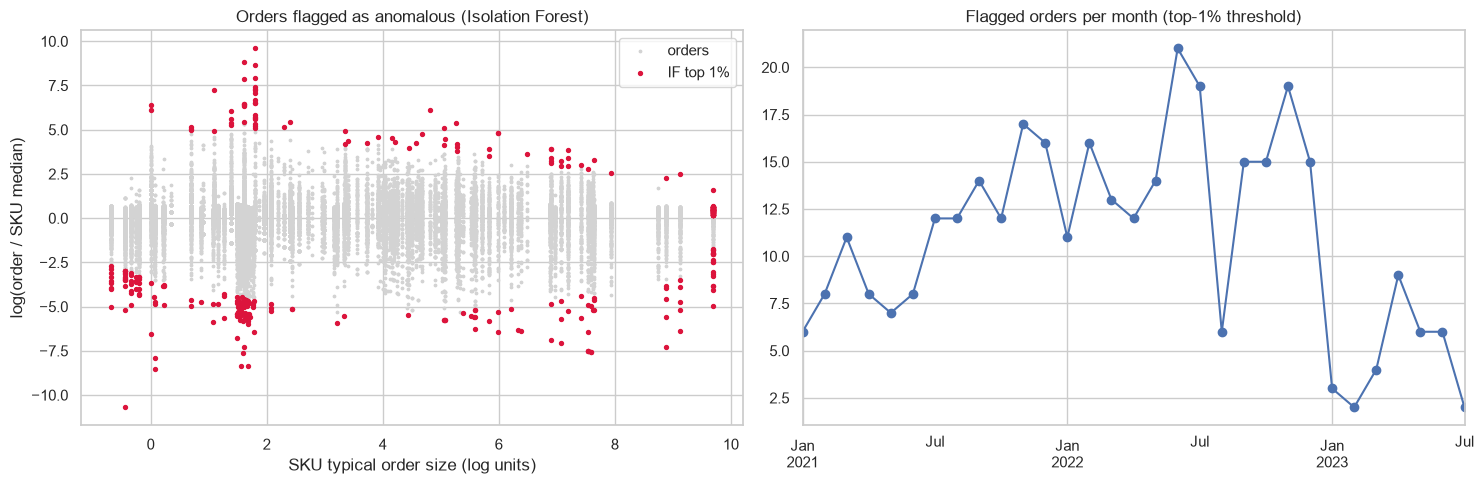

In [8]:
N_FLAG = int(0.01 * len(s))
flag = {n: np.zeros(len(s), bool) for n in sc0}
for n, sc in sc0.items(): flag[n][np.argsort(-sc)[:N_FLAG]] = True
agree = pd.DataFrame(flag)
print("Overlap of top-1% sets (number of orders):")
display(pd.DataFrame({a: {b: int((agree[a] & agree[b]).sum()) for b in agree} for a in agree}))
print("Flagged by >=2 detectors:", int((agree.sum(axis=1) >= 2).sum()), "| number of detectors flagging each order (among flagged):", agree.sum(axis=1)[agree.any(axis=1)].value_counts().sort_index().to_dict())

rev = s.copy(); rev["x_sku_median"] = np.exp(F0["rel"]); rev["if_score"] = sc0["Isolation Forest"]; rev["mad_z"] = sc0["SKU MAD z-score"]; rev["mad_z_up"] = sc0["SKU MAD z (upper tail)"]
rev["n_detectors"] = agree.sum(axis=1).values
top = rev[agree["Isolation Forest"].values].sort_values("if_score", ascending=False)
print("\nTop-1%% IF orders: %d are ABOVE and %d BELOW the SKU's median order size; %d are > 10x and %d are < 0.1x the SKU median" % (
    (top["x_sku_median"] > 1).sum(), (top["x_sku_median"] < 1).sum(), (top["x_sku_median"] > 10).sum(), (top["x_sku_median"] < 0.1).sum()))
print("Orders with quantity < 1 unit in the whole file: %d (%.1f%%) - fractional entries (kg) or unit-of-measure mismatches" % ((s["Order Quantity"] < 1).sum(), 100 * (s["Order Quantity"] < 1).mean()))
print("Share of flagged orders by customer type:", top["Customer Type"].value_counts(normalize=True).round(3).to_dict(), "| all orders:", rev["Customer Type"].value_counts(normalize=True).round(3).to_dict())
cols = ["Order Number", "Order Date", "SKU ID", "Warehouse ID", "Customer Type", "Order Quantity", "x_sku_median", "mad_z", "n_detectors"]
print("Top-10 by Isolation Forest (both tails):"); display(top[cols].head(10).round(4))
spikes = rev[agree["SKU MAD z (upper tail)"].values].sort_values("mad_z_up", ascending=False)
print("Top-10 upward spikes (SKU MAD z-score, upper tail) - the cases a planner would review as possible keying errors / bulk orders:")
display(spikes[cols[:7] + ["mad_z_up", "n_detectors"]].head(10).round(2))
spikes.to_csv(OUT / "kaizen_upward_spikes_top1pct.csv", index=False)
top.to_csv(OUT / "kaizen_flagged_orders_top1pct.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].scatter(F0["sku_med"], F0["rel"], s=3, c="lightgrey", label="orders")
ax[0].scatter(F0.loc[agree["Isolation Forest"].values, "sku_med"], F0.loc[agree["Isolation Forest"].values, "rel"], s=8, c="crimson", label="IF top 1%")
ax[0].set_xlabel("SKU typical order size (log units)"); ax[0].set_ylabel("log(order / SKU median)"); ax[0].legend(); ax[0].set_title("Orders flagged as anomalous (Isolation Forest)")
sc_ = rev.groupby(rev["Order Date"].dt.to_period("M").dt.to_timestamp())["if_score"].apply(lambda v: (v >= np.sort(rev["if_score"])[-N_FLAG]).sum())
sc_.plot(ax=ax[1], marker="o"); ax[1].set_title("Flagged orders per month (top-1% threshold)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig(OUT / "03_kaizen_flagged_orders.png", dpi=130); plt.show()

## Conclusions and limitations

**Part A - AI4I sensors (10,000 records, 3.39% failures; labels used only for scoring)**

| Detector | ROC-AUC | PR-AUC | Precision@339 | Lift vs random |
|---|---|---|---|---|
| Isolation Forest | 0.855 | 0.226 | 0.274 | 8.1x |
| LOF (k=100) | 0.860 | 0.289 | 0.324 | 9.6x |
| Max abs z-score | 0.851 | 0.232 | 0.286 | 8.4x |
| Robust Mahalanobis (MCD) | 0.828 | 0.187 | 0.136 | 4.0x |
| *Supervised RF reference (5-fold CV)* | *0.974* | *0.850* | - | - |

1. Without seeing a single label, the unsupervised detectors rank true failures well above chance (ROC-AUC 0.83-0.86; PR-AUC 0.19-0.29 vs a 0.034 base rate). Reviewing the 339 highest-scoring machines (3.4%) finds 14-32% of all failures with 27-32% precision for the best three. A supervised model reaches ROC-AUC 0.974 / PR-AUC 0.850, so labels are worth a lot when they exist; unsupervised detection is a screening tool, not a replacement.
2. **Which failures are found depends on the failure mechanism.** Power failures (PWF) are caught best (max-z 94%, LOF 81%, IF 73% of PWF in the top-K) because they sit at extreme torque/speed combinations. Overstrain (OSF) is caught at 16-35%, heat-dissipation (HDF) 1-11%, tool-wear (TWF) 4-15%, and random failures (RNF, 19 cases) at 0% - they are random by construction and cannot be seen in the sensors.
3. LOF is sensitive to `n_neighbors` (ROC-AUC 0.79 at k=20, 0.85 at k=50, 0.86 at k=100/200). k=100 was fixed a priori (~sqrt(n)); k=200 would have scored slightly higher but was **not** selected on the labels. The MCD Mahalanobis distance is the weakest because the failure region is not an elliptical tail of the joint distribution.

**Part B - Kaizen orders (33,919 orders; no labels -> synthetic-injection check)**

Recall of injected anomalies (1% of orders multiplied by a factor) within the top-2% flagged, mean of 5 seeds:

| Multiplier | Isolation Forest | LOF | SKU MAD z (two-sided) | SKU MAD z (upper tail) |
|---|---|---|---|---|
| x3 | 4% | 10% | 4% | 15% |
| x10 | 11% | 3% | 16% | **52%** |
| x30 | 24% | 1% | 44% | **76%** |

4. Detection depends strongly on the magnitude: a x3 error is within the normal spread of order sizes and essentially cannot be told apart; at x10-x30 a per-SKU robust z-score restricted to the upper tail finds half to three quarters of injected spikes. The generic multivariate detectors do worse because order quantities are extremely heavy-tailed in **both** directions (8.9% of orders are below one unit - fractional kg or unit-of-measure entries), so natural low-side outliers crowd the top of the ranking. LOF on these features mostly flags low-density SKU scales rather than unusual orders (no overlap with the other detectors) and is not suitable as configured.
5. On the real data, the top-1% of Isolation Forest scores (339 orders) split 148 above and 191 below the SKU's median order; 75 are >10x and 183 are <0.1x the median. The most actionable list for a planner is the **upward-spike list** (`kaizen_upward_spikes_top1pct.csv`), e.g. SO-019314 (616 units for a SKU whose median order is 1), SO-026881 and SO-051790 (88,200 and 33,600 units, 14,700x and 5,600x the SKU median); orders flagged by all three non-LOF detectors are the strongest candidates for review. No ground truth exists, so these are candidates, not confirmed errors.

**Limitations**
- AI4I is synthetic, and its failure labels are rule-based (threshold conditions on wear, power, temperature difference), which favours detectors operating on those quantities; results may not transfer to real machines.
- The review budget K = 3.39% uses the known failure rate; in practice the budget would come from inspection capacity, and the contamination rate is unknown.
- The injection test only covers multiplicative upward errors and counts naturally unusual orders as false positives (precision is therefore understated). It says nothing about other anomaly types (duplicated orders, wrong SKU, timing).
- Order anomalies were scored cross-sectionally (per SKU); no time/seasonality, customer or warehouse context was used.
- Score thresholds are not calibrated to probabilities; Isolation Forest results vary slightly by seed (std shown in the injection table).